In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
COLUMNS = [
    "layer", "oof_acc", "oof_macro_f1",
    "fold_acc_mean", "fold_acc_std",
    "best_epoch_mean", "train_time_sec",
]

WHISPER = [
    (1, .656669, .655725, .656665, .015187, 12.8, 680.8),
    (2, .674465, .675058, .674463, .009848, 19.2, 821.6),
    (3, .697061, .697158, .697059, .012118, 21.2, 854.2),
    (4, .693261, .693060, .693262, .007844, 16.0, 746.9),
    (5, .711858, .712088, .711859, .008238, 36.2, 1177.1),
    (6, .716457, .716534, .716458, .010756, 20.8, 850.8),
    (7, .718256, .718714, .718256, .016128, 19.6, 825.9),
    (8, .722256, .723144, .722254, .010904, 18.2, 797.0),
    (9, .729454, .730378, .729455, .008717, 20.8, 853.1),
    (10, .732853, .732449, .732853, .010167, 23.2, 897.1),
    (11, .743651, .744320, .743650, .012859, 12.0, 667.5),
    (12, .755449, .755841, .755447, .007604, 14.6, 724.8),
    (13, .763647, .763963, .763646, .011452, 15.8, 747.4),
    (14, .768246, .768857, .768244, .015140, 17.8, 785.9),
    (15, .765447, .766391, .765446, .008528, 14.0, 704.2),
    (16, .777245, .777508, .777245, .008190, 19.6, 827.2),
    (17, .780244, .781186, .780246, .013306, 13.8, 701.8),
    (18, .786443, .787791, .786442, .009032, 19.4, 823.1),
    (19, .788842, .789653, .788842, .009096, 10.8, 640.5),
    (20, .796241, .797232, .796239, .014896, 13.0, 688.2),
    (21, .793041, .793698, .793043, .017829, 15.4, 738.0),
    (22, .792042, .793331, .792041, .013035, 12.6, 679.2),
    (23, .781644, .782101, .781644, .012244, 5.2, 523.9),
    (24, .790842, .792000, .790842, .016938, 11.2, 650.4),
    (25, .793041, .794148, .793041, .016635, 13.8, 703.4),
    (26, .788442, .790075, .788441, .017756, 19.0, 819.8),
    (27, .788042, .789105, .788042, .012985, 17.6, 791.4),
    (28, .790242, .791716, .790245, .019313, 23.0, 897.3),
    (29, .783443, .785141, .783447, .019660, 12.2, 674.4),
    (30, .772645, .773995, .772649, .013074, 24.0, 923.4),
    (31, .770646, .772021, .770650, .013472, 23.2, 903.9),
    (32, .763647, .764723, .763646, .013372, 15.4, 670.6),
]

CRISPER = [
    (1, .636073, .635468, .636072, .011048, 19.6, 823.1),
    (4, .675265, .674608, .675262, .014447, 25.0, 946.8),
    (8, .705859, .705643, .705861, .015343, 12.0, 669.2),
    (12, .747051, .747403, .747051, .023235, 14.2, 718.4),
    (16, .773645, .774800, .773649, .013777, 17.2, 780.7),
    (20, .787842, .789473, .787842, .014565, 11.8, 669.5),
    (24, .790042, .791750, .790045, .015991, 7.0, 570.2),
    (28, .789042, .789854, .789044, .010020, 15.6, 752.3),
    (32, .779444, .780399, .779447, .020371, 10.0, 577.4),
]

whisper_df = pd.DataFrame(WHISPER, columns=COLUMNS)
crisper_df = pd.DataFrame(CRISPER, columns=COLUMNS)

In [3]:

METRICS = {
    "oof_acc": ("OOF Accuracy", 100, "%"),
    "oof_macro_f1": ("OOF Macro F1", 100, "%"),
    "fold_acc_mean": ("Mean Fold Accuracy", 100, "%"),
    "fold_acc_std": ("Fold Accuracy Std", 100, "pp"),
    "best_epoch_mean": ("Mean Best Epoch", 1, "epochs"),
    "train_time_sec": ("Total CV Training Time", 1, "seconds"),
}

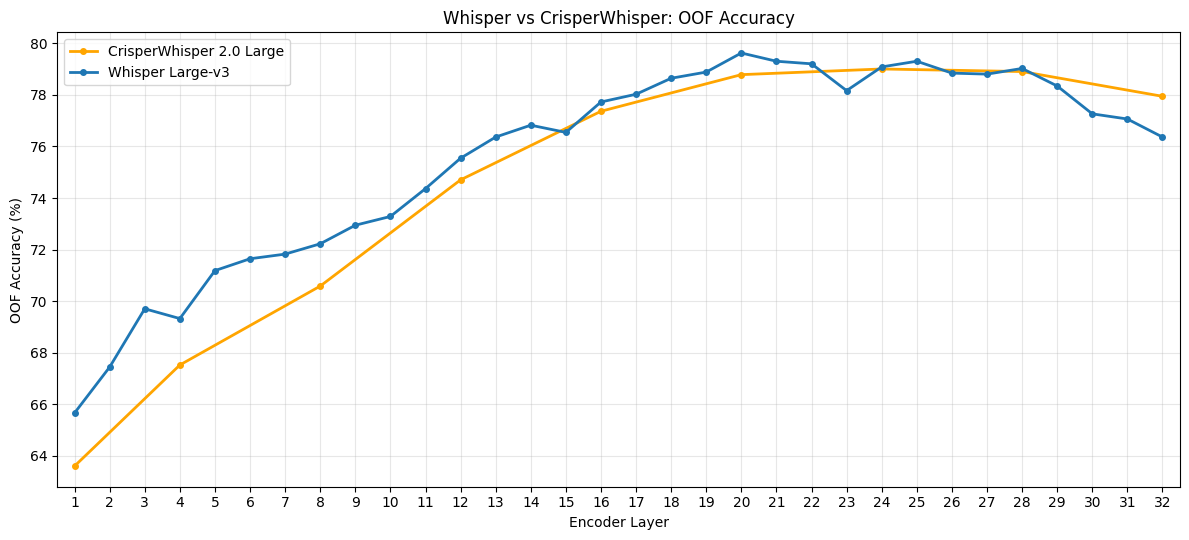

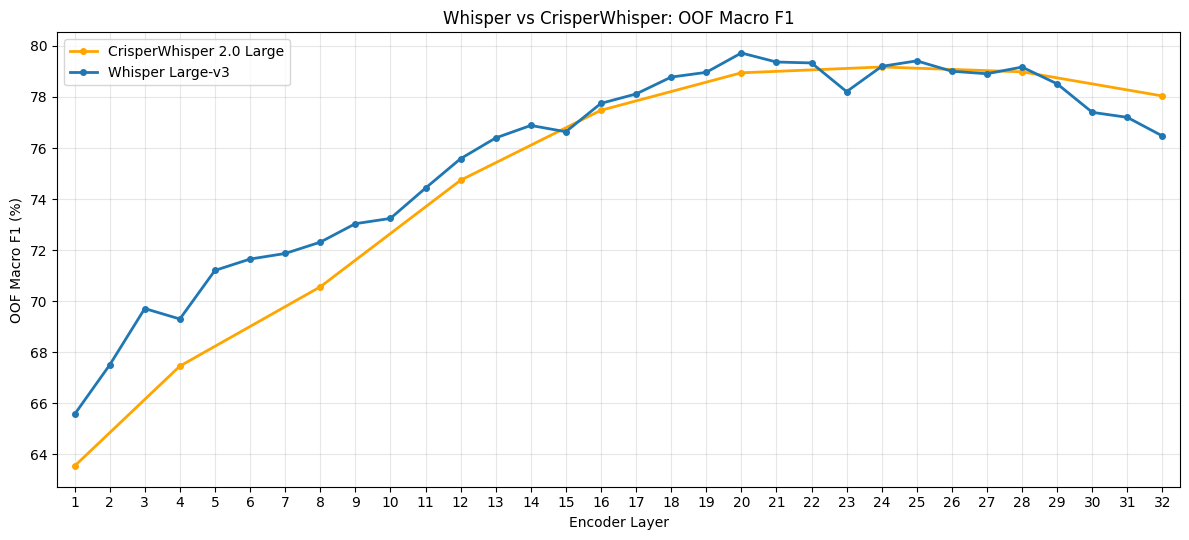

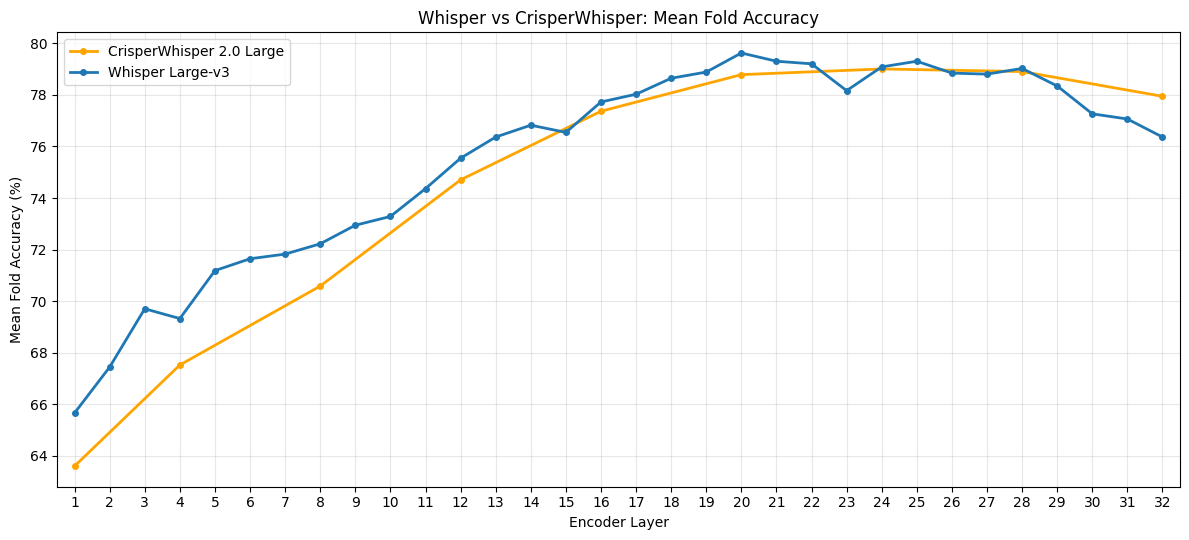

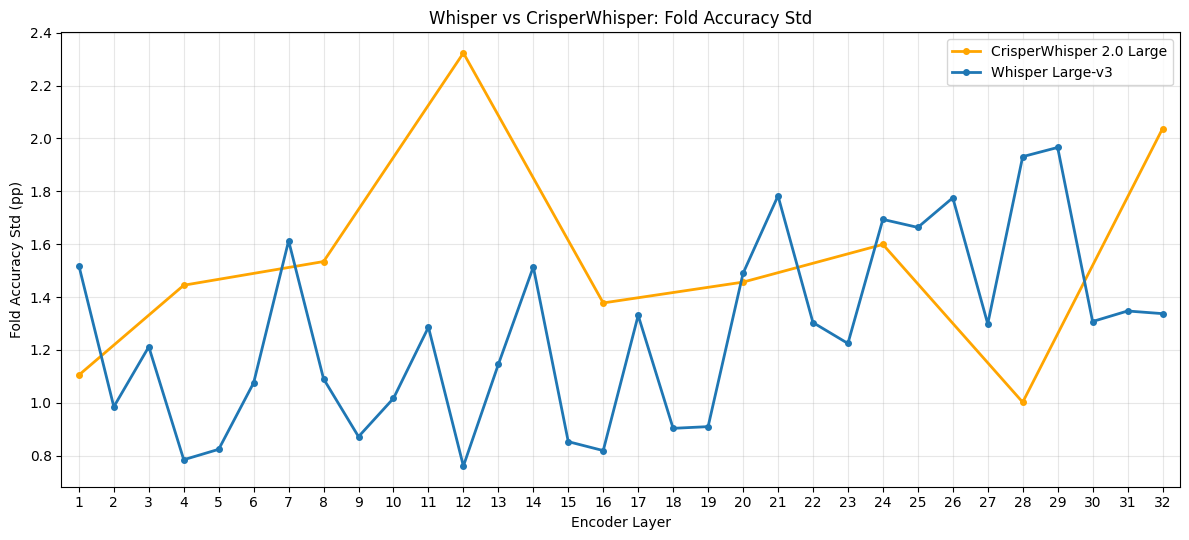

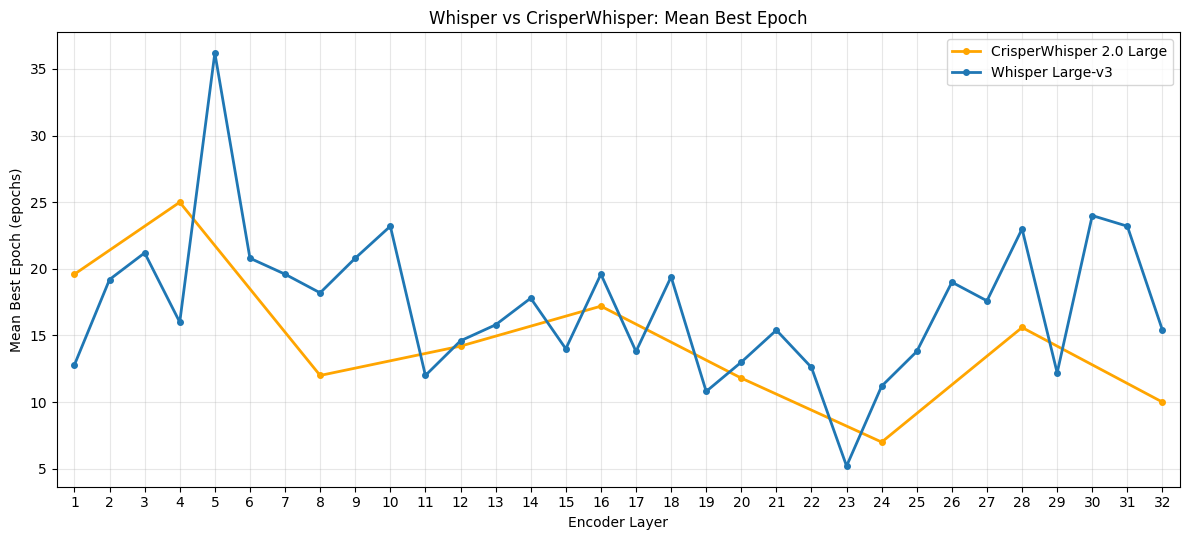

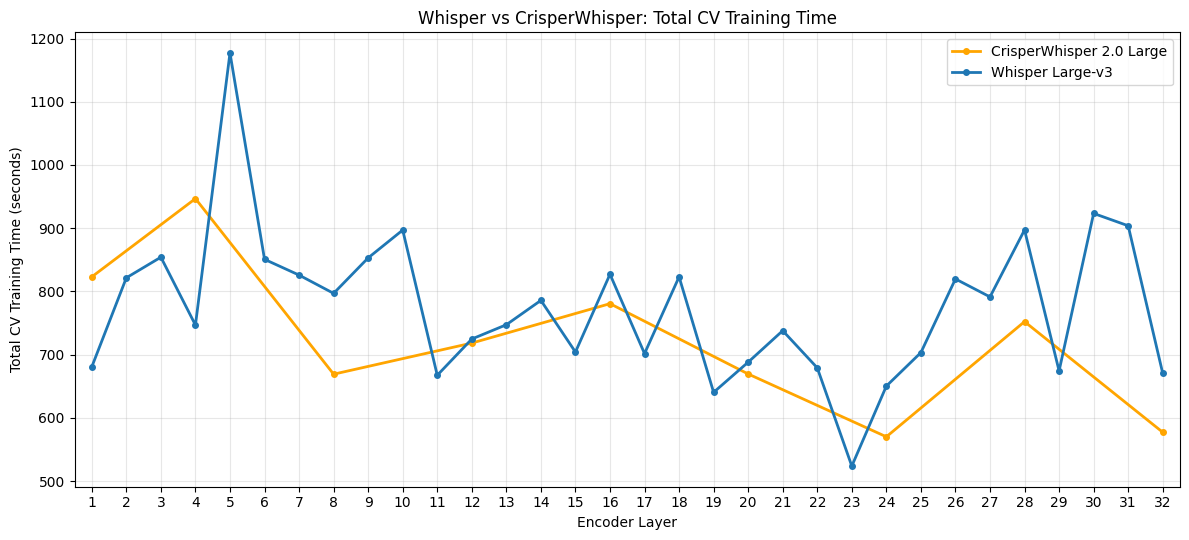

In [4]:
for metric, (title, scale, unit) in METRICS.items():
    fig, ax = plt.subplots(figsize=(12, 5.5))

    ax.plot(
        crisper_df["layer"],
        crisper_df[metric] * scale,
        color="orange",
        marker='o',
        markersize=4,
        linewidth=2,
        label="CrisperWhisper 2.0 Large",
    )

    ax.plot(
        whisper_df["layer"],
        whisper_df[metric] * scale,
        marker='o',
        markersize=4,
        linewidth=2,
        label="Whisper Large-v3",
    )

    ax.set_title(f"Whisper vs CrisperWhisper: {title}")
    ax.set_xlabel("Encoder Layer")
    ax.set_ylabel(f"{title} ({unit})")
    ax.set_xticks(range(1, 33))
    ax.set_xlim(0.5, 32.5)
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()
    plt.close(fig)

In [5]:
# Report best tested layer
for name, df in [
    ("Whisper Large-v3", whisper_df),
    ("CrisperWhisper 2.0", crisper_df),
]:
    row = df.loc[df["oof_acc"].idxmax()]
    print(
        f"{name}: Layer {int(row['layer'])}, "
        f"OOF Acc = {row['oof_acc']:.4%}, "
        f"Macro F1 = {row['oof_macro_f1']:.4%}"
    )


Whisper Large-v3: Layer 20, OOF Acc = 79.6241%, Macro F1 = 79.7232%
CrisperWhisper 2.0: Layer 24, OOF Acc = 79.0042%, Macro F1 = 79.1750%
